# Machine Learning Python NoteBook


## 1. Project framing


### 1.1 Context: Hotel Revenue Management

*Revenue management* (RM) refers to the strategies and tactics used by a company to manage the allocation
of a fixed capacity across different customer and price classes over time in order to maximise revenue. 
Born in the US airline industry after the 1978 deregulation, it later spread to hotels,
car rentals and cruise lines, that is, to industries facing the same problem of limited and perishable
capacity [1].

The hotel industry meets the conditions that make RM relevant :
- **fixed and immediately perishable capacity**: a room left empty on a given night cannot be stored and
  sold later;
- **advance bookings**: the hotel observes future demand before it materialises and can adjust its
  decisions accordingly;
- **several prices for the same product**: the same room is sold at different rates depending on the
  segment, the channel, the booking date or the cancellation conditions.

#### The cancellation problem
A booking is not a guaranteed sale. The customer may cancel before arrival or fail to show up (*no-show*).
For a hotel, every late cancellation means a potentially empty room,
and therefore lost revenue.

The classical response is **overbooking**: accepting more bookings than available rooms, in anticipation
that some customers will not arrive. This decision is a risky trade-off: overbooking too little leaves rooms
empty, while overbooking too much forces the hotel to relocate guests elsewhere, which is costly in both
compensation and reputation.
**The quality of this decision depends directly on the ability to predict which bookings will be
cancelled.**

#### Pricing and segmentation
Two other RM levers are addressed in this project:
- **price**: understanding which factors (season, room type, channel, group composition) explain the
  average price paid per night;
- **segmentation**: identifying groups of customers with distinct behaviours. Price differentiation relies
  precisely on the existence of such segments, separated by "fences" (booking lead time, cancellation
  conditions, channel).

#### The role of machine learning
Machine learning is one of the factors accelerating the development of pricing and RM, but
we have to be careful about the idea that a model trained on its own can set the "right price". The
effective approach would be to **combine machine learning predictions with simple economic assumptions and an
optimisation step** [1]. This is the logic followed here: predictive models are not an
end in themselves, but they feed a management decision.

#### Research question
> *To what extent can machine learning models, trained on the booking history of two hotels, predict
> cancellations, explain observed prices and identify customer segments, and how can these predictions
> improve an overbooking decision?*




### 1.2 Objectives

#### General objective
Build, compare and interpret a broad set of machine learning models (supervised and unsupervised) applied
to hotel bookings, following a rigorous experimental protocol, and then show how these models can support a
revenue management decision.

#### Specific objectives

**O1 — Classification: predicting booking cancellation**
- Target: is_canceled (1 = booking cancelled, 0 = stay completed).
- Question: using the information available at booking time, can we estimate the probability that a
  booking will be cancelled?
- Models compared: logistic regression, k-nearest neighbours, decision tree, Random Forest, SVM, gradient
  boosting.
- Evaluation: ROC-AUC, accuracy, precision, recall, F1.

**O2 — Regression: explaining and predicting the average daily rate (ADR)**
- Target: adr (*Average Daily Rate*).
- Question: which factors determine the price paid per night, and how accurately can it be predicted?
- Models compared: Dummy baseline, linear regression, Ridge, Lasso, ElasticNet, and a Ridge regression 
- Evaluation: RMSE, MAE, MAPE, weighted MAPE, R².

**O3 — Unsupervised learning: customer segmentation**
- No target: bookings are grouped according to their behavioural characteristics.
- Question: do natural customer segments exist, and do they match the commercial segments declared by the
  hotel?
- Methods compared: k-means, Gaussian mixture model, hierarchical clustering (Ward); PCA for visualisation.
- Evaluation: silhouette, Davies-Bouldin, Calinski-Harabasz, cluster profiling, Adjusted Rand Index against
  market_segment.

**O4 — Decision: simulating an overbooking policy**
- Use the probabilities from O1 (and the observed or O2-predicted prices) to compute a booking limit
  following the risk-based approach described by Phillips [1, ch. 11, pp. 281-292].
- Compare, over the test period, the simulated net revenue of three policies: no overbooking, overbooking
  based on a single average cancellation rate, and overbooking based on the model's probabilities.

### 1.3 Data: *Hotel Booking Demand*

#### Origin
The data come from the article by Antonio, Almeida and Nunes (2019) [2]. They were extracted directly from
the *Property Management Systems* of two hotels located in Portugal:
- **H1 - Resort Hotel**
- **H2 - City Hotel**

They cover bookings with an arrival date between **1 July 2015 and 31 August 2017**, including cancelled
bookings. The version used here is the one published on Kaggle, which merges the two original files into a single
one and adds a "hotel" column to distinguish them: **119,390 bookings and 32 columns**
(40,060 for the Resort Hotel, 79,330 for the City Hotel).

#### Relevance for the project
This dataset makes it possible to address the three required tasks from a single business problem: a
binary target for classification (is_canceled), a continuous target for regression (adr), and a
variety of behavioural variables for segmentation. These are real-world data, with the associated imperfections (missing values,
undefined categories, outliers), which have to be handled.

#### Data dictionary

| Group | Variable | Description | Known at booking time? |
|---|---|---|---|
| Hotel | `hotel` | Resort Hotel or City Hotel | Yes |
| **Target** | `is_canceled` | 1 if the booking was cancelled, 0 otherwise | First target |
| Calendar | `lead_time` | Number of days between booking and arrival date | Yes |
| Calendar | `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, `arrival_date_day_of_month` | Planned arrival date | Yes |
| Stay | `stays_in_weekend_nights`, `stays_in_week_nights` | Number of weekend / weekday nights booked | Yes |
| Guests | `adults`, `children`, `babies` | Group composition | Yes |
| Guests | `country` | Country of origin (ISO code) | Yes |
| Guests | `is_repeated_guest` | 1 if the guest has stayed at the hotel before | Yes |
| Guests | `previous_cancellations` | Number of previous bookings cancelled by the customer | Yes |
| Guests | `previous_bookings_not_canceled` | Number of previous bookings not cancelled | Yes |
| Guests | `customer_type` | Customer type: Transient, Contract, Group, Transient-Party | Yes |
| Commercial | `market_segment` | Market segment (e.g. TA = travel agent, TO = tour operator) | Yes |
| Commercial | `distribution_channel` | Distribution channel | Yes |
| Commercial | `agent`, `company` | ID of the travel agency or company that made the booking | Yes |
| Product | `meal` | Meal plan (BB, HB, FB, SC / Undefined) | Yes |
| Product | `reserved_room_type` | Room type booked (anonymised code) | Yes |
| Product | `deposit_type` | Deposit type: No Deposit, Non Refund, Refundable | Yes |
| Product | `required_car_parking_spaces` | Number of parking spaces requested | Yes (to be checked) |
| Product | `total_of_special_requests` | Number of special requests | Yes (to be checked) |
| **Target** | `adr` | Average Daily Rate (average price per night) | Second target |
| Tracking | `booking_changes` | Number of changes until arrival or cancellation | **To be monitored** |
| Tracking | `days_in_waiting_list` | Days on the waiting list before confirmation | **To be monitored** |
| Leakage | `assigned_room_type` | Room type actually assigned | No |
| Leakage | `reservation_status` | Final status: Canceled, Check-Out, No-Show | No |
| Leakage | `reservation_status_date` | Date of the last status change | No |

#### Known limitations at this stage
- **Only two hotels**, in Portugal, over 2015-2017: generalisation to other properties or periods is not
  guaranteed.
- **Unknown capacity**: the number of rooms in each hotel is not provided; it will have to be estimated for
  the overbooking simulation.
- **Censored demand**: only completed bookings are observed, never the customers who decided not to book.
  The dataset therefore does not allow estimating a true price-response curve.

#### References
[1] R. L. Phillips, *Pricing and Revenue Optimization*, 2nd ed. Stanford, CA: Stanford Business Books, 2021.

[2] N. Antonio, A. de Almeida and L. Nunes, "Hotel booking demand datasets," *Data in Brief*, vol. 22, pp. 41-49, 2019, doi: 10.1016/j.dib.2018.11.126.

## 2. Data Understanding and Cleaning

### 2.1 Setup and data loading

In [2]:
# Required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR = "data"
RAW_PATH = os.path.join(DATA_DIR, "hotel_bookings.csv")
CLEAN_PATH = os.path.join(DATA_DIR, "hotel_bookings_clean.csv")

if not os.path.exists(RAW_PATH):
    raise FileNotFoundError(f"Dataset not found at {RAW_PATH}. Place hotel_bookings.csv in the data/ folder.")

df_raw = pd.read_csv(RAW_PATH)
print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Shape: 119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 2.2 First look: structure and types

In [4]:
print(df_raw["hotel"].value_counts(), "\n")
print("Arrival years:", df_raw["arrival_date_year"].value_counts().sort_index().to_dict())

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64 

Arrival years: {2015: 21996, 2016: 56707, 2017: 40687}


**Observations.**
- The dataset contains 119,390 bookings and 32 columns: 79,330 for the City Hotel and 40,060 for the Resort
  Hotel, which matches the figures reported in the source article.
- 2015 and 2017 are partial years (July–December 2015 and January–August 2017), so yearly counts must not be
  compared directly.

### 2.3 Missing values

,n_missing,pct_missing
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


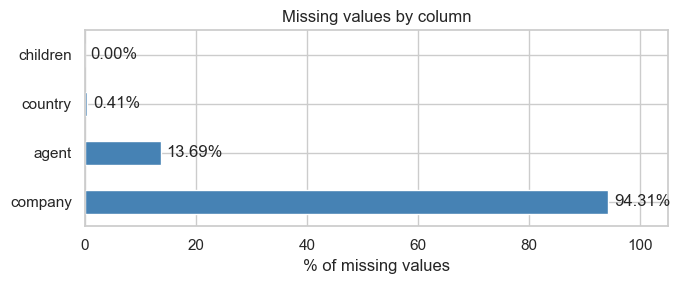

In [5]:
missing = df_raw.isna().sum() #Count the number of empty cells
missing = missing[missing > 0].sort_values(ascending=False) #Order them
missing_pct = (missing / len(df_raw) * 100).round(2) #Create pourcentage
display(pd.DataFrame({"n_missing": missing, "pct_missing": missing_pct}))

#Create an histogram
fig, ax = plt.subplots(figsize=(7, 3))
missing_pct.plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("% of missing values")
ax.set_title("Missing values by column")
for i, v in enumerate(missing_pct):
    ax.text(v + 1, i, f"{v:.2f}%", va="center")
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

**Interpretation and decisions.**

| Column | Missing | Meaning | Decision |
|---|---|---|---|
| `company` | 94.3% | The booking was not made by a company | Do not impute an ID: create a binary flag `has_company` |
| `agent` | 13.7% | The booking was not made through a travel agent | Create a binary flag `has_agent`; keep the ID as a category for possible later encoding |
| `country` | 0.41% | Country not recorded | Replace with the category `"Unknown"` |
| `children` | 4 rows | Value not recorded | Replace with 0 (the most frequent value) |

### 2.4 Duplicate rows

The dataset has no booking identifier, so identical rows cannot be distinguished.


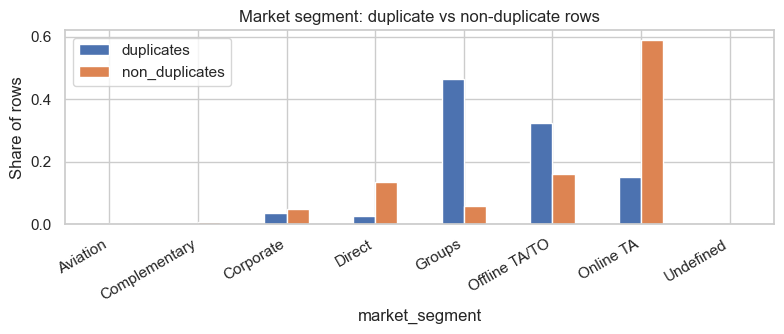

Exact duplicate rows: 31,994 (26.8%)
Cancellation rate - duplicates: 63.1% | non-duplicates: 27.5%


In [6]:
dup_mask = df_raw.duplicated(keep="first")

comp = pd.DataFrame({
    "duplicates": df_raw.loc[dup_mask, "market_segment"].value_counts(normalize=True),
    "non_duplicates": df_raw.loc[~dup_mask, "market_segment"].value_counts(normalize=True),
}).round(3)

fig, ax = plt.subplots(figsize=(8, 3.5))
comp.plot.bar(ax=ax)
ax.set_ylabel("Share of rows")
ax.set_title("Market segment: duplicate vs non-duplicate rows")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(f"Exact duplicate rows: {dup_mask.sum():,} ({dup_mask.mean():.1%})")
print(f"Cancellation rate - duplicates: {df_raw.loc[dup_mask, 'is_canceled'].mean():.1%} | "
      f"non-duplicates: {df_raw.loc[~dup_mask, 'is_canceled'].mean():.1%}")

**Interpretation.**
- About 27% of the rows (31,994) are exact copies of another row.
- Duplicates are strongly over-represented in the **Groups** and **Offline TA/TO** segments, and their
  cancellation rate (about 63%) is much higher than that of non-duplicates (about 27%).
- The most plausible explanation is that each row corresponds to one room: a group or a tour operator
  booking several identical rooms on the same dates generates identical rows. These are therefore probably
  real bookings, not data-entry errors.

**Decision.**
- **Keep the duplicates** in the main dataset. For the overbooking problem, ten identical rooms are ten rooms
  that may or may not be occupied; removing them would distort both the cancellation rate and the occupancy.

### 2.5 Categorical variables: undefined and inconsistent categories

In [7]:
cat_cols = ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type",
            "customer_type", "reserved_room_type", "assigned_room_type", "reservation_status"]
for c in cat_cols:
    print(f"{c} ({df_raw[c].nunique()} levels):", df_raw[c].value_counts().to_dict(), "\n")
print("Countries:", df_raw["country"].nunique(), "| Agents:", df_raw["agent"].nunique(),
      "| Companies:", df_raw["company"].nunique())

hotel (2 levels): {'City Hotel': 79330, 'Resort Hotel': 40060} 

meal (5 levels): {'BB': 92310, 'HB': 14463, 'SC': 10650, 'Undefined': 1169, 'FB': 798} 

market_segment (8 levels): {'Online TA': 56477, 'Offline TA/TO': 24219, 'Groups': 19811, 'Direct': 12606, 'Corporate': 5295, 'Complementary': 743, 'Aviation': 237, 'Undefined': 2} 

distribution_channel (5 levels): {'TA/TO': 97870, 'Direct': 14645, 'Corporate': 6677, 'GDS': 193, 'Undefined': 5} 

deposit_type (3 levels): {'No Deposit': 104641, 'Non Refund': 14587, 'Refundable': 162} 

customer_type (4 levels): {'Transient': 89613, 'Transient-Party': 25124, 'Contract': 4076, 'Group': 577} 

reserved_room_type (10 levels): {'A': 85994, 'D': 19201, 'E': 6535, 'F': 2897, 'G': 2094, 'B': 1118, 'C': 932, 'H': 601, 'P': 12, 'L': 6} 

assigned_room_type (12 levels): {'A': 74053, 'D': 25322, 'E': 7806, 'F': 3751, 'G': 2553, 'C': 2375, 'B': 2163, 'H': 712, 'I': 363, 'K': 279, 'P': 12, 'L': 1} 

reservation_status (3 levels): {'Check-Out': 75166

**Observations and decisions.**
- `meal`: according to the source article, `Undefined` and `SC` both mean "no meal package". The 1,169
  `Undefined` values are merged into `SC`.
- `market_segment` (2 rows) and `distribution_channel` (5 rows) contain an `Undefined` category. These rows
  (5 in total, since some overlap) are negligible and are removed.
- `country` (177 levels), `agent` (333) and `company` (352) are **high-cardinality** variables. Grouping rare
  countries into `"Other"` is deferred to the preprocessing pipeline (Phase 4), because the list of frequent
  countries must be computed on the training set only; computing it here on the full dataset would be a
  (mild) form of leakage.

### 2.6 Numerical variables: impossible and extreme values

In [8]:
num_cols = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
            "babies", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]

total_guests = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
total_nights = df_raw["stays_in_weekend_nights"] + df_raw["stays_in_week_nights"]
checks = {
    "No guest (adults + children + babies = 0)": (total_guests == 0).sum(),
    "Zero nights": (total_nights == 0).sum(),
    "Zero nights with ADR > 0": ((total_nights == 0) & (df_raw["adr"] > 0)).sum(),
    "Negative ADR": (df_raw["adr"] < 0).sum(),
    "ADR = 0": (df_raw["adr"] == 0).sum(),
    "ADR > 1000": (df_raw["adr"] > 1000).sum(),
    "adults >= 10": (df_raw["adults"] >= 10).sum(),
    "children >= 10 or babies >= 9": ((df_raw["children"] >= 10) | (df_raw["babies"] >= 9)).sum(),
}
display(pd.Series(checks, name="n_rows").to_frame())

print(f"lead_time: median = {df_raw['lead_time'].median():.0f} days | max = {df_raw['lead_time'].max()} days")
print("Two highest ADR values:", df_raw["adr"].nlargest(2).tolist())

,n_rows
No guest (adults + children + babies = 0),180
Zero nights,715
Zero nights with ADR > 0,0
Negative ADR,1
ADR = 0,1959
ADR > 1000,1
adults >= 10,13
children >= 10 or babies >= 9,3


lead_time: median = 69 days | max = 737 days
Two highest ADR values: [5400.0, 510.0]


**Interpretation and decisions.**

| Issue | Rows | Decision | Justification |
|---|---|---|---|
| No guest at all | 180 | Remove | A booking with no guest is not a real stay |
| Negative ADR | 1 | Remove | A price cannot be negative |
| ADR = 5,400 | 1 | Remove | About 10 times the next highest value (510) for a 2-adult, 1-night City Hotel booking: almost certainly an entry error |
| `adults` ≥ 10 | 13 | Remove | Very large groups recorded as a single booking, all cancelled with ADR = 0: inconsistent with the "one row = one room" logic |
| `children` = 10, `babies` ≥ 9 | 3 | Remove | Implausible for one room |
| ADR = 0 | 1,959 | **Keep**, but exclude from regression | The largest group is `Complementary` (free) stays (680), the rest is spread across all segments; they are real bookings for the cancellation problem but not meaningful prices |
| Zero nights | 715 | **Keep**, but exclude from regression | Probably day-use rooms; all have ADR = 0 and a much lower cancellation rate (about 5%) |

The distribution of `lead_time` is very right-skewed (median 69 days, maximum 737 days). This is not an error:
some bookings are made more than a year ahead.

### 2.7 Consistency between the target and the reservation status

In [9]:
pd.crosstab(df_raw["reservation_status"], df_raw["is_canceled"], margins=True)

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


**Interpretation.**

- `is_canceled = 1` means that the **guest did not stay** at the hotel. It includes both **cancellations** (43,017) and **no-shows** (1,207). This is the quantity we want to predict for **overbooking**.

- Before cleaning, the overall **non-stay rate is 37.0%**: 41.7% for the City Hotel and 27.8% for the Resort Hotel.

- `reservation_status` is a **perfect copy of the target**. Using it as a feature would allow the model to know the answer directly, giving a perfect score without actually learning anything. This is called **data leakage**. It must therefore be removed, along with `reservation_status_date`, which contains information about when the cancellation occurred.

### 2.8 Data leakage audit

A variable leaks information if its value is only known **after** the event we want to predict. Here, the
prediction is made at booking time. Beyond the obvious cases above, four variables need to be checked
because they may be updated until arrival.

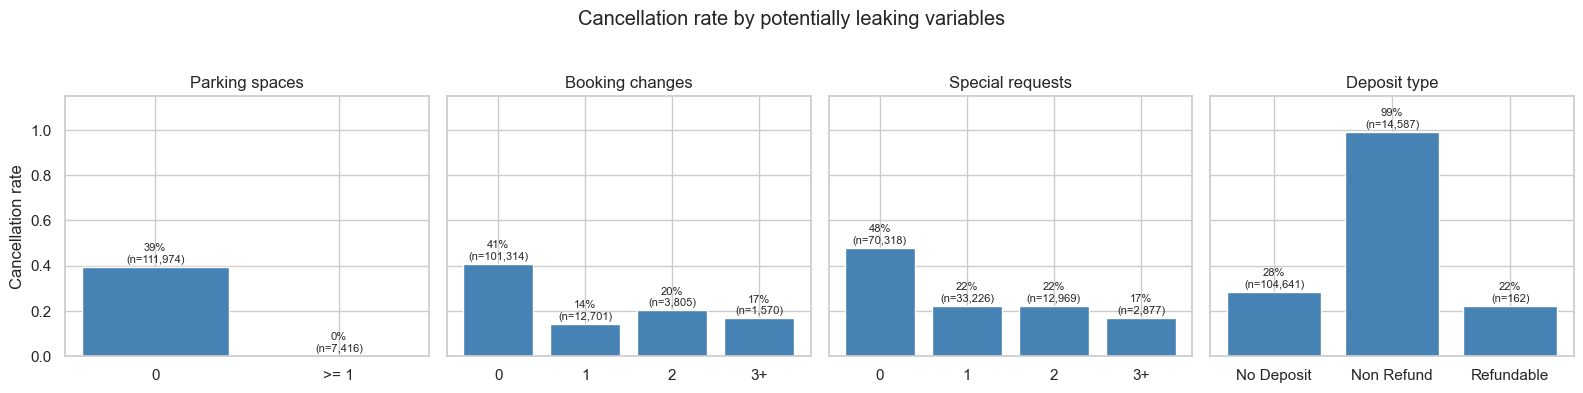

In [10]:
audit = df_raw.copy()
audit["parking_requested"] = np.where(audit["required_car_parking_spaces"] > 0, ">= 1", "0")
audit["n_changes"] = audit["booking_changes"].clip(upper=3).astype(str).replace({"3": "3+"})
audit["n_requests"] = audit["total_of_special_requests"].clip(upper=3).astype(str).replace({"3": "3+"})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col, title in zip(
    axes,
    ["parking_requested", "n_changes", "n_requests", "deposit_type"],
    ["Parking spaces", "Booking changes", "Special requests", "Deposit type"],
):
    rates = audit.groupby(col)["is_canceled"].agg(["mean", "size"]).sort_index()
    ax.bar(rates.index, rates["mean"], color="steelblue")
    for i, (m, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(i, m + 0.02, f"{m:.0%}\n(n={n:,})", ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, 1.15)
axes[0].set_ylabel("Cancellation rate")
plt.suptitle("Cancellation rate by potentially leaking variables", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation.**

- `required_car_parking_spaces`: **none** of the 7,416 bookings with parking were cancelled. This suggests the variable may be recorded **at arrival**, so it is excluded from the cancellation model.

- `booking_changes`: bookings with no changes have a higher cancellation rate (41%) than bookings with changes (14–20%). Since changes may occur **until cancellation or check-in**, it is therefore excluded from the cancellation model.

- `total_of_special_requests`: the cancellation rate decreases as requests increase, but there is no deterministic pattern. Since requests are known at booking time, the variable is **kept**.

- `deposit_type = Non Refund`: **99.4%** of these bookings are cancelled, which is unexpected. This is considered a **data anomaly**, but not leakage, since the deposit type is known at booking time. The variable is **kept**, and this anomaly should be kept in mind when interpreting the results.

- `assigned_room_type`: only known **at arrival**, so it is excluded from the model and used only for EDA.

- `days_in_waiting_list`: known **before confirmation**, so it is **kept** in the model.

### 2.9 Cleaning

All cleaning decisions are applied in a single function



In [11]:
def clean_bookings(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the cleaning decisions of sections 2.3 to 2.8. Returns the clean data and a removal log."""
    df = df.copy()
    log = []

    def drop(mask, reason):
        nonlocal df
        log.append({"step": reason, "rows_removed": int(mask.sum())})
        df = df.loc[~mask].copy()

    # Duplicates are flagged (not removed): analysis only, never a model feature
    df["is_duplicate"] = df.duplicated(keep="first").astype(int)

    # Missing values
    df["children"] = df["children"].fillna(0).astype(int)
    df["country"] = df["country"].fillna("Unknown")
    df["has_agent"] = df["agent"].notna().astype(int)
    df["has_company"] = df["company"].notna().astype(int)
    df["agent"] = df["agent"].fillna(0).astype(int).astype(str).replace("0", "None")
    df = df.drop(columns=["company"])  # 94% missing: information kept in has_company

    # Inconsistent categories
    df["meal"] = df["meal"].replace("Undefined", "SC")
    drop((df["market_segment"] == "Undefined") | (df["distribution_channel"] == "Undefined"),
         "Undefined market segment or distribution channel")

    # Impossible or extreme values
    drop((df["adults"] + df["children"] + df["babies"]) == 0, "No guest")
    drop(df["adr"] < 0, "Negative ADR")
    drop(df["adr"] > 1000, "ADR > 1000 (entry error)")
    drop(df["adults"] >= 10, "adults >= 10")
    drop((df["children"] >= 10) | (df["babies"] >= 9), "children >= 10 or babies >= 9")

    return df.reset_index(drop=True), pd.DataFrame(log)

df, removal_log = clean_bookings(df_raw)
display(removal_log)
print(f"Rows before: {len(df_raw):,} | after: {len(df):,} | removed: {len(df_raw) - len(df):,} "
      f"({(len(df_raw) - len(df)) / len(df_raw):.2%})")
print(f"Cancellation rate after cleaning: {df['is_canceled'].mean():.1%}")

,step,rows_removed
0,Undefined market segment or distribution channel,5
1,No guest,180
2,Negative ADR,1
3,ADR > 1000 (entry error),1
4,adults >= 10,13
5,children >= 10 or babies >= 9,3


Rows before: 119,390 | after: 119,187 | removed: 203 (0.17%)
Cancellation rate after cleaning: 37.1%


Only 0.17% of the rows are removed, and the cancellation rate is virtually unchanged (37.0% before, 37.1% after). Cleaning therefore corrects
errors without biasing the data.

### 2.10 Feature engineering

In [12]:
month_map = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"], start=1)}

df["arrival_month_num"] = df["arrival_date_month"].map(month_map)
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"],
                                         month=df["arrival_month_num"],
                                         day=df["arrival_date_day_of_month"]))
df["booking_date"] = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
df["arrival_weekday"] = df["arrival_date"].dt.day_name()
df["season"] = df["arrival_month_num"].map(
    {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
     6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["has_kids"] = ((df["children"] + df["babies"]) > 0).astype(int)
df["is_domestic"] = (df["country"] == "PRT").astype(int)
df["room_type_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)  # EDA only

| New variable | Definition | Purpose |
|---|---|---|
| `arrival_date` | Date rebuilt from the year, month and day columns | Time series, temporal train/test split |
| `booking_date` | `arrival_date` − `lead_time` | Booking-time perspective, alternative split criterion |
| `arrival_month_num`, `arrival_weekday`, `season` | Calendar attributes of the arrival | Seasonality of demand and prices |
| `total_nights` | Weekend nights + weekday nights | Length of stay |
| `total_guests`, `has_kids` | Group size and presence of children or babies | Family vs. individual/business profiles |
| `is_domestic` | 1 if the guest comes from Portugal | Portugal is the main market and has a very different cancellation behaviour |
| `has_agent`, `has_company` | Booking made through an agent / a company | Booking channel, replaces the sparse ID columns |
| `room_type_changed` | Assigned room ≠ booked room | **EDA only** (known at arrival) |

### 2.11 Feature sets by task

The variables allowed for each task are defined explicitly here, so that leakage cannot be introduced by
mistake in later phases.

In [13]:
LEAKAGE_COLS = ["reservation_status", "reservation_status_date", "assigned_room_type", "room_type_changed"]
ANALYSIS_ONLY = ["is_duplicate", "arrival_date", "booking_date", "arrival_date_year"]

BASE_FEATURES = [
    "hotel", "lead_time", "arrival_month_num", "arrival_date_week_number", "arrival_date_day_of_month",
    "arrival_weekday", "season", "stays_in_weekend_nights", "stays_in_week_nights", "total_nights",
    "adults", "children", "babies", "total_guests", "has_kids", "meal", "country", "is_domestic",
    "market_segment", "distribution_channel", "is_repeated_guest", "previous_cancellations",
    "previous_bookings_not_canceled", "reserved_room_type", "deposit_type", "agent", "has_agent",
    "has_company", "days_in_waiting_list", "customer_type", "total_of_special_requests",
]

# O1 - Classification: features known at booking time; suspected leaking variables excluded
CLF_TARGET = "is_canceled"
CLF_FEATURES = BASE_FEATURES + ["adr"]

# O2 - Regression: ADR on bookings with ADR > 0 and at least one night
REG_TARGET = "adr"
REG_FEATURES = BASE_FEATURES

# O3 - Clustering: behavioural variables, duplicates removed (variables selected in Phase 7)
assert not set(CLF_FEATURES) & set(LEAKAGE_COLS), "Leakage column in classification features"
print(f"Classification: {len(CLF_FEATURES)} features | Regression: {len(REG_FEATURES)} features")
print(f"Regression sample: {((df['adr'] > 0) & (df['total_nights'] > 0)).sum():,} bookings")

Classification: 32 features | Regression: 31 features
Regression sample: 117,390 bookings


### 2.12 Saving the clean dataset

In [14]:
os.makedirs(DATA_DIR, exist_ok=True)
df.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH, df.shape)
# To reload later in the notebooks: the command is the following 
# df = pd.read_csv(CLEAN_PATH, parse_dates=["arrival_date", "booking_date"])

Saved: data\hotel_bookings_clean.csv (119187, 44)


### 2.13 Summary


#### Rows
- **Before:** 119,390 rows × 32 columns → **After:** 119,187 rows × 44 columns (**203 rows removed, 0.17%**).
- Cancellation rate virtually unchanged: 37.0% → 37.1%.

| Rows removed | Count |
|---|---|
| Undefined market segment or distribution channel | 5 |
| No guest (adults + children + babies = 0) | 180 |
| Negative ADR | 1 |
| ADR > 1,000 (entry error: 5,400) | 1 |
| `adults` ≥ 10 | 13 |
| `children` ≥ 10 or `babies` ≥ 9 | 3 |

**Kept on purpose:** 31,994 duplicate rows (likely individual rooms of group bookings, flagged with
`is_duplicate`), bookings with ADR = 0 and bookings with zero nights.

#### Columns removed or modified
| Column | Action |
|---|---|
| `company` | **Removed** (94% missing), replaced by `has_company` |
| `children` | Missing values → 0 |
| `country` | Missing values → `"Unknown"` |
| `agent` | Missing values → `"None"`, treated as categorical |
| `meal` | `Undefined` merged into `SC` (no meal package) |

#### Columns added (13)
| Column | Description | Use |
|---|---|---|
| `arrival_date` | Full arrival date | Analysis, temporal split |
| `booking_date` | `arrival_date` − `lead_time` | Analysis, temporal split |
| `arrival_month_num` | Arrival month (1–12) | Feature |
| `arrival_weekday` | Arrival day of the week | Feature |
| `season` | Season of arrival | Feature |
| `total_nights` | Weekend + weekday nights | Feature |
| `total_guests` | Adults + children + babies | Feature |
| `has_kids` | 1 if children or babies | Feature |
| `is_domestic` | 1 if guest from Portugal | Feature |
| `has_agent` | 1 if booked through an agent | Feature |
| `has_company` | 1 if booked through a company | Feature |
| `is_duplicate` | 1 if exact copy of a previous row | Analysis only |
| `room_type_changed` | Assigned room ≠ booked room | EDA only (leakage) |

#### Columns excluded from all models
| Column | Reason |
|---|---|
| `reservation_status` | Exact copy of the target |
| `reservation_status_date` | Date of the cancellation itself |
| `assigned_room_type`, `room_type_changed` | Only known at arrival |
| `is_duplicate`, `arrival_date`, `booking_date`, `arrival_date_year` | Analysis / split only |
| `arrival_date_month` | Redundant with `arrival_month_num` |

#### Feature sets by task

**Common features (31):** `hotel`, `lead_time`, `arrival_month_num`, `arrival_date_week_number`,
`arrival_date_day_of_month`, `arrival_weekday`, `season`, `stays_in_weekend_nights`, `stays_in_week_nights`,
`total_nights`, `adults`, `children`, `babies`, `total_guests`, `has_kids`, `meal`, `country`, `is_domestic`,
`market_segment`, `distribution_channel`, `is_repeated_guest`, `previous_cancellations`,
`previous_bookings_not_canceled`, `reserved_room_type`, `deposit_type`, `agent`, `has_agent`, `has_company`,
`days_in_waiting_list`, `customer_type`, `total_of_special_requests`.

| | Classification (O1) | Regression (O2) |
|---|---|---|
| **Target** | `is_canceled` | `adr` |
| **Features** | 31 common + `adr` = **32** | 31 common |
| **Sample** | All 119,187 bookings | 117,390 bookings with ADR > 0 and at least one night |
| **Excluded (suspected leakage)** | `required_car_parking_spaces`, `booking_changes` (suspected leakage) | `is_canceled` (outcome not known at booking) |

**Clustering (O3):** duplicates removed; variables selected in Phase 7.


## 3. Exploratory Data Analysis

### 3.1 Cancellation: who cancels?

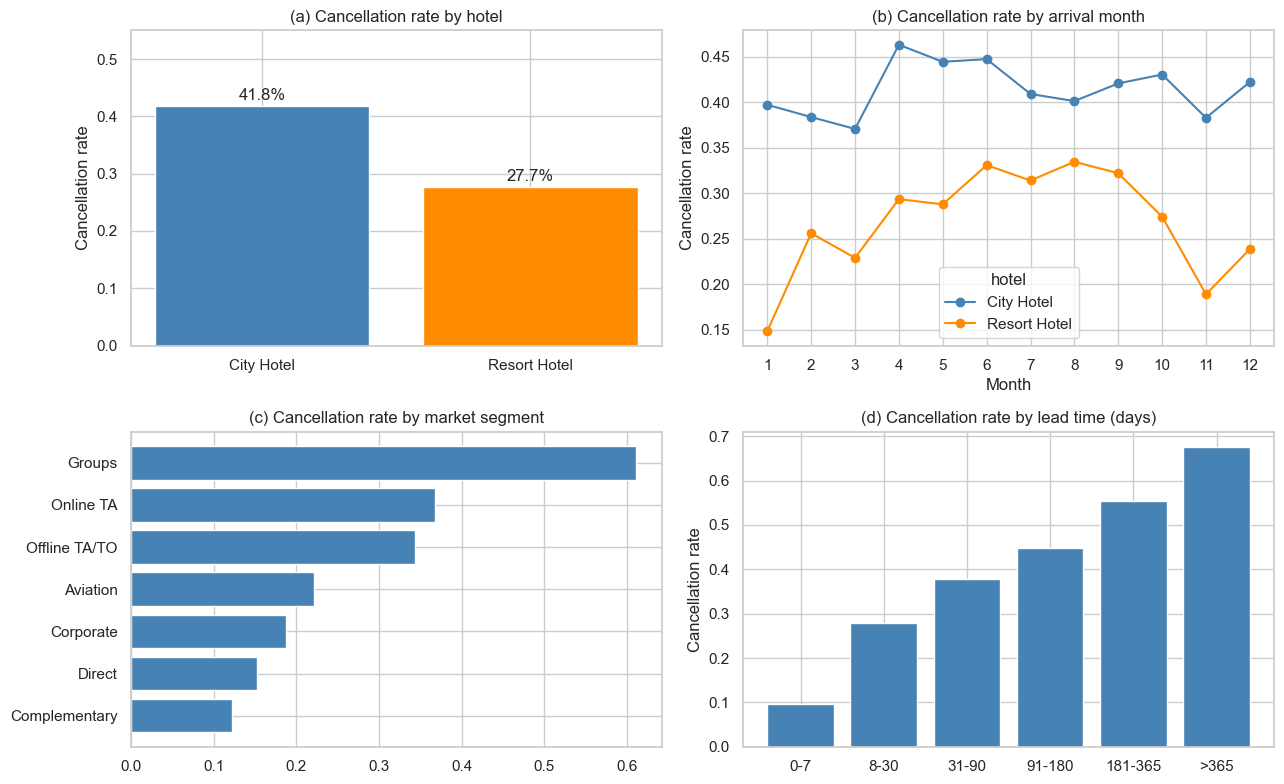

Domestic guests: 56.7% | Foreign guests: 23.6%


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# (a) By hotel
rate_hotel = df.groupby("hotel")["is_canceled"].mean()
axes[0, 0].bar(rate_hotel.index, rate_hotel.values, color=["steelblue", "darkorange"])
for i, v in enumerate(rate_hotel.values):
    axes[0, 0].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[0, 0].set_title("(a) Cancellation rate by hotel")
axes[0, 0].set_ylim(0, 0.55)

# (b) By arrival month
rate_month = df.groupby(["arrival_month_num", "hotel"])["is_canceled"].mean().unstack()
rate_month.plot(ax=axes[0, 1], marker="o", color=["steelblue", "darkorange"])
axes[0, 1].set_title("(b) Cancellation rate by arrival month")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_xticks(range(1, 13))

# (c) By market segment
rate_seg = df.groupby("market_segment")["is_canceled"].mean().sort_values()
axes[1, 0].barh(rate_seg.index, rate_seg.values, color="steelblue")
axes[1, 0].set_title("(c) Cancellation rate by market segment")

# (d) By lead time
lead_bins = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
                   labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])
rate_lead = df.groupby(lead_bins, observed=True)["is_canceled"].mean()
axes[1, 1].bar(rate_lead.index.astype(str), rate_lead.values, color="steelblue")
axes[1, 1].set_title("(d) Cancellation rate by lead time (days)")

for ax in axes.flat:
    ax.set_ylabel("Cancellation rate" if ax is not axes[1, 0] else "")
plt.tight_layout()
plt.show()

print(f"Domestic guests: {df.loc[df['is_domestic'] == 1, 'is_canceled'].mean():.1%} | "
      f"Foreign guests: {df.loc[df['is_domestic'] == 0, 'is_canceled'].mean():.1%}")

**Interpretation.**
- **Class balance**: 37% of the bookings are cancelled.
- **(a) Hotel**: the City Hotel cancels much more often (41.8%) than the Resort Hotel (27.7%). The hotel must be a
  feature.
- **(b) Month**: at the City Hotel the rate is high all year. At the Resort Hotel it is clearly seasonal:
  low in winter and higher in summer.
- **(c) Segment**: `Groups` cancel most (61%), followed by online and offline travel agents (34–37%), while
  `Direct` and `Corporate` bookings cancel far less (15–19%). The booking channel is highly informative.
- **(d) Lead time**: the cancellation rate rises steadily with the lead time, from 10% for last-minute
  bookings to 68% for bookings made more than a year ahead. This is the strongest pattern observed and supports
  the following idea: the longer the wait, the more opportunities to change plans.
- **Origin**: Portuguese guests cancel much more (56.7%) than foreign guests (23.6%)

### 3.2 Price: what drives the Average Daily Rate (ADR)?

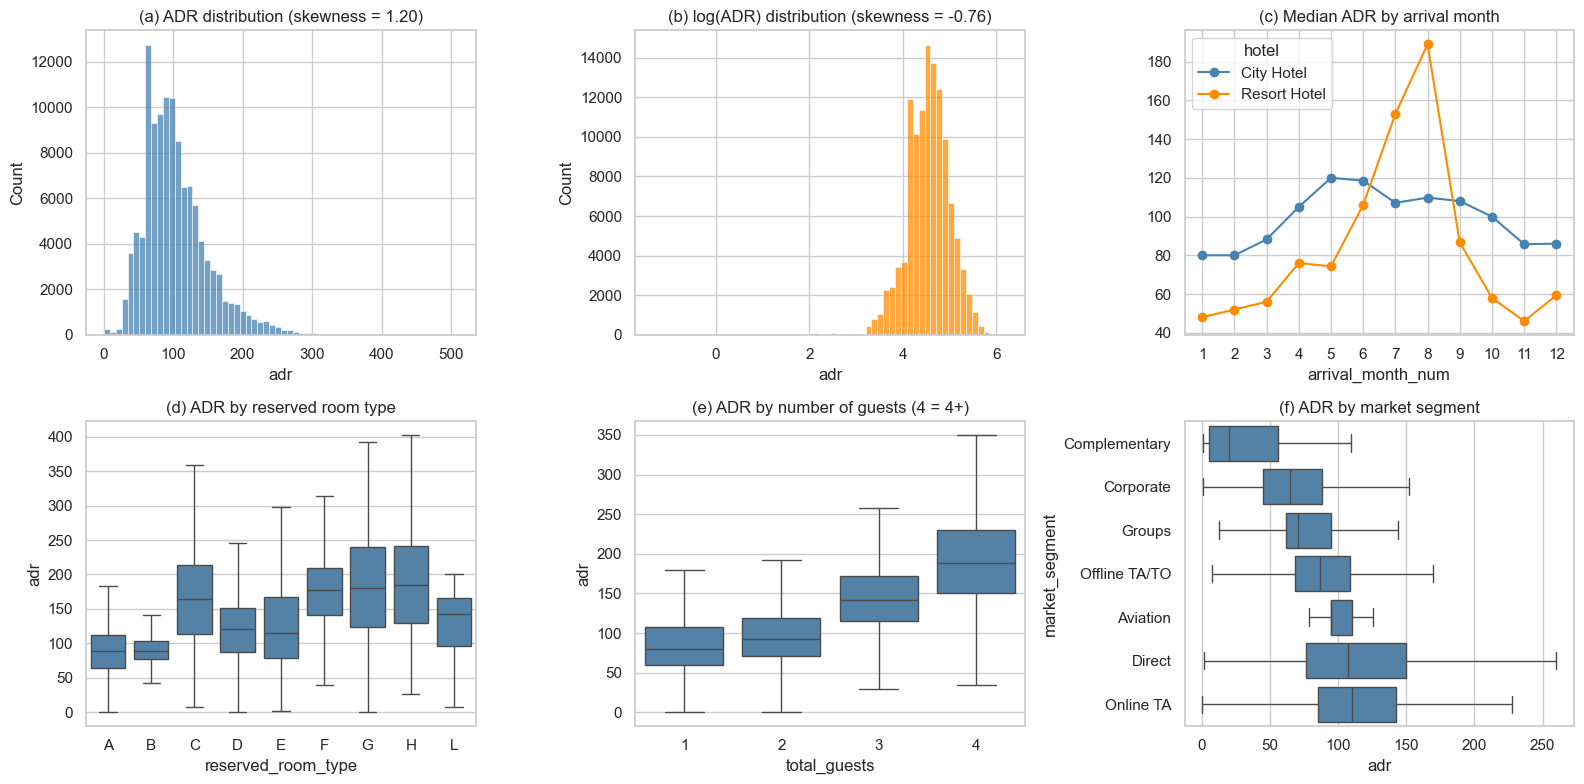

In [16]:
reg_df = df[(df["adr"] > 0) & (df["total_nights"] > 0)]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# (a) Distribution and (b) log-distribution
sns.histplot(reg_df["adr"], bins=60, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title(f"(a) ADR distribution (skewness = {reg_df['adr'].skew():.2f})")
sns.histplot(np.log(reg_df["adr"]), bins=60, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title(f"(b) log(ADR) distribution (skewness = {np.log(reg_df['adr']).skew():.2f})")

# (c) Seasonality by hotel
adr_month = reg_df.groupby(["arrival_month_num", "hotel"])["adr"].median().unstack()
adr_month.plot(ax=axes[0, 2], marker="o", color=["steelblue", "darkorange"])
axes[0, 2].set_title("(c) Median ADR by arrival month")
axes[0, 2].set_xticks(range(1, 13))

# (d) Room type
order = sorted(reg_df["reserved_room_type"].unique())
sns.boxplot(data=reg_df, x="reserved_room_type", y="adr", order=order, ax=axes[1, 0],
            color="steelblue", showfliers=False)
axes[1, 0].set_title("(d) ADR by reserved room type")

# (e) Group size
sns.boxplot(data=reg_df, x=reg_df["total_guests"].clip(upper=4), y="adr", ax=axes[1, 1],
            color="steelblue", showfliers=False)
axes[1, 1].set_title("(e) ADR by number of guests (4 = 4+)")

# (f) Market segment
seg_order = reg_df.groupby("market_segment")["adr"].median().sort_values().index
sns.boxplot(data=reg_df, y="market_segment", x="adr", order=seg_order, ax=axes[1, 2],
            color="steelblue", showfliers=False)
axes[1, 2].set_title("(f) ADR by market segment")

plt.tight_layout()
plt.show()

**Interpretation.**
- **(a, b) Distribution**: the ADR is right-skewed (median €95, maximum €510). The log transformation reduces the
  skewness but overcorrects it (negative skewness), because a few very small ADR values create a long left tail.
- **(c) Seasonality**: this is the dominant effect, and it differs strongly between hotels. At the Resort Hotel the
  median ADR is about four times higher in August (€189) than in November (€46). At the City Hotel prices vary
  much less (€80–120), with peaks in spring. The interaction **hotel × month** is therefore essential.
- **(d) Room type**: room types C, F, G and H are much more expensive than types A and B. Room type is a product characteristic.
- **(e) Group size**: the price increases with the number of guests (median €80 for one guest, €188 for four or
  more), because larger groups book larger rooms.
- **(f) Segment**: customer-related variables also matter (`Complementary` and `Corporate` are the cheapest,
  `Direct` and `Online TA` the most expensive), but with large overlaps.

### 3.3 Correlations between numerical variables

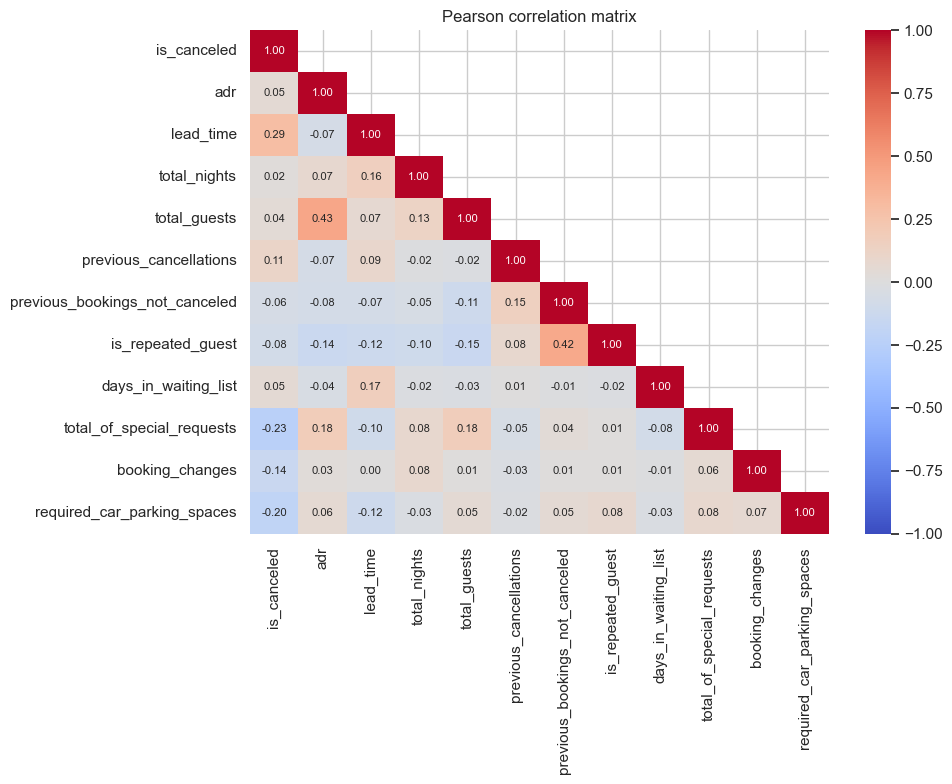

In [17]:
corr_cols = ["is_canceled", "adr", "lead_time", "total_nights", "total_guests", "previous_cancellations",
             "previous_bookings_not_canceled", "is_repeated_guest", "days_in_waiting_list",
             "total_of_special_requests", "booking_changes", "required_car_parking_spaces"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            ax=ax, annot_kws={"size": 8})
ax.set_title("Pearson correlation matrix")
plt.tight_layout()
plt.show()

**Interpretation.**
- **Linear correlations are weak overall.** With the target `is_canceled`, the strongest are `lead_time` (+0.29),
  `total_of_special_requests` (−0.23) and `required_car_parking_spaces` (−0.20, excluded for leakage). With
  `adr`, the strongest is `total_guests` (+0.43).
- Weak linear correlations do not mean weak relationships: sections 3.1 and 3.2 show strong **non-linear** and
  **categorical** effects (segment, deposit type, month × hotel). Non-linear models (trees, boosting, KNN) are
  therefore expected to outperform linear ones.

## 4. Experimental Protocol

This phase defines the rules shared by all supervised models (Phases 5 and 6), so that every model is trained and
evaluated under the same conditions and without data leakage:
1. a **temporal train/test split**;
2. a **preprocessing pipeline** fitted on the training set only;
3. a **cross-validation strategy** for hyperparameter tuning, the test set being used only once at the end.

### 4.1 Temporal train/test split

In practice, a model is trained on past bookings and used to predict future ones. A random split would mix past
and future and would place identical rows in both sets, making the test score
over-optimistic

In [18]:
SPLIT_DATE = "2017-01-01"

def temporal_split(data, features, target, split_date=SPLIT_DATE):
    """Train = arrivals before split_date, test = arrivals from split_date. Sorted by arrival date."""
    data = data.sort_values("arrival_date")
    train = data[data["arrival_date"] < split_date]
    test = data[data["arrival_date"] >= split_date]
    return train[features], test[features], train[target], test[target]

# O1 - Classification: all bookings
X_train_clf, X_test_clf, y_train_clf, y_test_clf = temporal_split(df, CLF_FEATURES, CLF_TARGET)

# O2 - Regression: bookings with ADR > 0 and at least one night
X_train_reg, X_test_reg, y_train_reg, y_test_reg = temporal_split(reg_df, REG_FEATURES, REG_TARGET)

summary = pd.DataFrame({
    "train_rows": [len(X_train_clf), len(X_train_reg)],
    "test_rows": [len(X_test_clf), len(X_test_reg)],
    "test_share": [len(X_test_clf) / len(df), len(X_test_reg) / len(reg_df)],
    "train_target_mean": [y_train_clf.mean(), y_train_reg.mean()],
    "test_target_mean": [y_test_clf.mean(), y_test_reg.mean()],
}, index=["Classification (is_canceled)", "Regression (adr)"]).round(3)
summary

,train_rows,test_rows,test_share,train_target_mean,test_target_mean
Classification (is_canceled),78568,40619,0.341,0.362,0.387
Regression (adr),77169,40221,0.343,97.010,115.950


### 4.2 Preprocessing pipeline

All transformations are learned on the training set only, inside a scikit-learn `Pipeline`. Each model will be
wrapped as `Pipeline([("prep", preprocessor), ("model", estimator)])`, so that cross-validation also refits the
preprocessing on each fold.

| Variable type | Variables | Transformation |
|---|---|---|
| Numerical | lead time, nights, guests, history, waiting list, requests, ADR (classification only) | Median imputation + standardisation |
| Binary | `has_kids`, `is_domestic`, `is_repeated_guest`, `has_agent`, `has_company` | Kept as is |
| Categorical (few levels) | hotel, month, weekday, season, meal, segment, channel, room type, deposit, customer type | One-hot encoding |
| Categorical (many levels) | `country`, `agent` | One-hot encoding, levels with fewer than 200 training bookings grouped into an "infrequent" category |

Standardisation is required by distance-based and regularised models (KNN, SVM, logistic regression, Ridge,
Lasso); it has no effect on tree-based models. Grouping rare countries and agents **inside** the pipeline ensures
that the list of frequent levels is computed on the training data only.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BINARY_COLS = ["has_kids", "is_domestic", "is_repeated_guest", "has_agent", "has_company"]
CAT_LOW_COLS = ["hotel", "arrival_month_num", "arrival_weekday", "season", "meal", "market_segment",
                "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"]
CAT_HIGH_COLS = ["country", "agent"]

def build_preprocessor(features, min_frequency=200):
    """Build the preprocessing step for a given list of features."""
    binary = [c for c in BINARY_COLS if c in features]
    cat_low = [c for c in CAT_LOW_COLS if c in features]
    cat_high = [c for c in CAT_HIGH_COLS if c in features]
    numeric = [c for c in features if c not in binary + cat_low + cat_high]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
        ("bin", "passthrough", binary),
        ("cat_low", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_low),
        ("cat_high", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                   sparse_output=False), cat_high),
    ])

# Sanity check: fit on train only, transform both sets
for name, feats, X_tr, X_te in [("Classification", CLF_FEATURES, X_train_clf, X_test_clf),
                                ("Regression", REG_FEATURES, X_train_reg, X_test_reg)]:
    prep = build_preprocessor(feats).fit(X_tr)
    print(f"{name}: {len(feats)} raw features -> {prep.transform(X_tr).shape[1]} encoded features | "
          f"test shape {prep.transform(X_te).shape}")

cat_high = build_preprocessor(CLF_FEATURES).fit(X_train_clf).named_transformers_["cat_high"]
for col in CAT_HIGH_COLS:
    n_cols = sum(name.startswith(f"{col}_") for name in cat_high.get_feature_names_out())
    print(f"{col}: {X_train_clf[col].nunique()} levels in train -> {n_cols} encoded columns (incl. 'infrequent')")

Classification: 32 raw features -> 150 encoded features | test shape (40619, 150)
Regression: 31 raw features -> 149 encoded features | test shape (40221, 149)
country: 160 levels in train -> 26 encoded columns (incl. 'infrequent')
agent: 285 levels in train -> 48 encoded columns (incl. 'infrequent')


### 4.3 Validation strategy and metrics

- **Hyperparameter tuning**: cross-validation on the training set only, with TimeSeriesSplit (5 folds). Each
  fold trains on earlier arrivals and validates on later ones, which reproduces the temporal logic of the
  train/test split.
- **Test set**: used **once**, at the end, to evaluate the final version of each model. Using it to choose models
  or hyperparameters would make the reported performance over-optimistic.

| Task | Main metric | Additional metrics |
|---|---|---|
| Classification | ROC-AUC | Accuracy, precision, recall, F1 |
| Regression | RMSE | MAE, R² |

In [20]:
from sklearn.model_selection import TimeSeriesSplit

CV = TimeSeriesSplit(n_splits=5)

CLF_SCORING = "roc_auc"                      # metric used to select hyperparameters (classification)
REG_SCORING = "neg_root_mean_squared_error"  # metric used to select hyperparameters (regression)

# Visual check of the folds on the classification training set
for i, (tr_idx, val_idx) in enumerate(CV.split(X_train_clf), start=1):
    dates = df.loc[X_train_clf.index, "arrival_date"]
    print(f"Fold {i}: train until {dates.iloc[tr_idx].max().date()} ({len(tr_idx):,} rows) | "
          f"validate {dates.iloc[val_idx].min().date()} -> {dates.iloc[val_idx].max().date()} ({len(val_idx):,} rows)")

Fold 1: train until 2015-10-08 (13,098 rows) | validate 2015-10-08 -> 2016-02-17 (13,094 rows)
Fold 2: train until 2016-02-17 (26,192 rows) | validate 2016-02-17 -> 2016-05-06 (13,094 rows)
Fold 3: train until 2016-05-06 (39,286 rows) | validate 2016-05-06 -> 2016-07-23 (13,094 rows)
Fold 4: train until 2016-07-23 (52,380 rows) | validate 2016-07-23 -> 2016-10-08 (13,094 rows)
Fold 5: train until 2016-10-08 (65,474 rows) | validate 2016-10-08 -> 2016-12-31 (13,094 rows)


## 5. Classification: Predicting Cancellations


**Objective.** Predict whether a booking will be cancelled using only the information available at booking time, and compare several families of classification models.

| Family | Model | Idea |
|---|---|---|
| Baseline | Dummy classifier | Always predicts the most frequent class (no cancellation) |
| Linear | Logistic regression | Weighted sum of the features turned into a probability |
| Distance-based | K-nearest neighbours (KNN) | Looks at the outcome of the most similar past bookings |
| Tree | Decision tree | Sequence of simple yes/no rules |
| Ensemble (bagging) | Random Forest | Average of many trees trained on random subsets |
| Kernel | Support Vector Machine (SVM) | Finds the boundary that best separates the two classes |
| Ensemble (boosting) | Gradient boosting | Trees added one by one, each correcting the errors of the previous ones |

### 5.1 Training and evaluation helpers

In [21]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

clf_results = {}   # test metrics of each model
clf_models = {}    # fitted best pipeline of each model

def get_scores(model, X):
    """Probability (or score) of cancellation, used for ROC-AUC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def train_and_evaluate(name, estimator, param_grid=None, X_train=X_train_clf, y_train=y_train_clf):
    """Tune the hyperparameters by cross-validation, then evaluate the best model once on the test set."""
    pipe = Pipeline([("prep", build_preprocessor(CLF_FEATURES)), ("model", estimator)])
    start = time.time()
    if param_grid:
        search = GridSearchCV(pipe, param_grid, cv=CV, scoring=CLF_SCORING, n_jobs=-1)
        search.fit(X_train, y_train)
        model, best_params, cv_auc = search.best_estimator_, search.best_params_, search.best_score_
    else:
        model, best_params, cv_auc = pipe.fit(X_train, y_train), {}, np.nan
    train_time = time.time() - start

    y_pred = model.predict(X_test_clf)
    clf_results[name] = {
        "cv_roc_auc": cv_auc,
        "accuracy": accuracy_score(y_test_clf, y_pred),
        "precision": precision_score(y_test_clf, y_pred, zero_division=0),
        "recall": recall_score(y_test_clf, y_pred),
        "f1": f1_score(y_test_clf, y_pred),
        "roc_auc": roc_auc_score(y_test_clf, get_scores(model, X_test_clf)),
        "train_time_s": train_time,
        "best_params": {k.replace("model__", ""): v for k, v in best_params.items()},
    }
    clf_models[name] = model
    r = clf_results[name]
    print(f"{name}: ROC-AUC = {r['roc_auc']:.3f} | F1 = {r['f1']:.3f} | "
          f"best params = {r['best_params']} | {train_time:.0f} s")

# KNN and SVM are slow on large datasets: they are trained on a regular subsample of the training set
# (every 4th / 8th booking), which keeps the chronological order required by TimeSeriesSplit.
X_train_sub4, y_train_sub4 = X_train_clf.iloc[::4], y_train_clf.iloc[::4]
X_train_sub8, y_train_sub8 = X_train_clf.iloc[::8], y_train_clf.iloc[::8]
print(f"Full training set: {len(X_train_clf):,} | 1/4 subsample: {len(X_train_sub4):,} | "
      f"1/8 subsample: {len(X_train_sub8):,}")

Full training set: 78,568 | 1/4 subsample: 19,642 | 1/8 subsample: 9,821


### 5.2 Dummy Classifier and Logistic Regression

- **Dummy classifier**: predicts "not cancelled" for every booking. Its accuracy equals the share of
  non-cancelled bookings, and its ROC-AUC is 0.5 (no better than chance). Any useful model must beat it.
- **Logistic regression**: the classical reference model for predicting a yes/no outcome. Hyperparameter **`C`** controls regularisation:
  a small `C` forces small coefficients (simpler model, less overfitting), a large `C` lets the model fit the
  training data more closely.

In [22]:
train_and_evaluate("Dummy", DummyClassifier(strategy="most_frequent"))

train_and_evaluate(
    "Logistic regression",
    LogisticRegression(max_iter=2000),
    {"model__C": [0.01, 0.1, 1, 10]},
)

Dummy: ROC-AUC = 0.500 | F1 = 0.000 | best params = {} | 1 s
Logistic regression: ROC-AUC = 0.860 | F1 = 0.641 | best params = {'C': 0.1} | 23 s


### 5.3 K-nearest neighbours (KNN)

A booking is classified according to the majority outcome among its **`n_neighbors`** most similar bookings in the
training set (Euclidean distance on standardised features). A small number of neighbours gives a very flexible but
noisy model (overfitting); a large number gives a smoother but less precise model (underfitting).
Trained on a quarter of the training set because the prediction step compares each booking with all stored
bookings.

In [23]:
train_and_evaluate(
    "KNN",
    KNeighborsClassifier(),
    {"model__n_neighbors": [5, 15, 51]},
    X_train=X_train_sub4, y_train=y_train_sub4,
)

c:\Users\ilyes\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\ilyes\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\ilyes\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ilyes\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "

KNN: ROC-AUC = 0.806 | F1 = 0.595 | best params = {'n_neighbors': 51} | 3 s


### 5.4 Decision tree

The tree splits the bookings with successive yes/no questions, choosing at each step
the question that best separates cancelled and non-cancelled bookings.
- **`max_depth`**: maximum number of successive questions. A deep tree memorises the training data (overfitting).
- **`min_samples_leaf`**: minimum number of bookings in each final group, which prevents rules based on very few
  cases.

In [24]:
train_and_evaluate(
    "Decision tree",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"model__max_depth": [5, 10, 20], "model__min_samples_leaf": [1, 50]},
)

Decision tree: ROC-AUC = 0.822 | F1 = 0.632 | best params = {'max_depth': 5, 'min_samples_leaf': 50} | 11 s


### 5.5 Random Forest

A Random Forest trains many decision trees, each on a random sample of the bookings and of the features, and
averages their predictions. Averaging many different trees reduces the overfitting of a single tree.
- **`n_estimators`** (fixed at 200): number of trees; more trees give more stable results but take longer.
- **`max_depth`**: depth of each tree, as for the single decision tree.

In [25]:
train_and_evaluate(
    "Random Forest",
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    {"model__max_depth": [10, 20, None]},
)

Random Forest: ROC-AUC = 0.868 | F1 = 0.567 | best params = {'max_depth': 10} | 46 s


### 5.6 Support Vector Machine (SVM)

The SVM looks for the boundary that separates the two classes with the largest possible margin. With the RBF
kernel, this boundary can be curved.
- **`C`**: trade-off between a wide margin (small `C`, simpler model) and few training errors (large `C`, more
  complex model).

Trained on one eighth of the training set, because its training time grows very quickly with the number of rows.

In [26]:
train_and_evaluate(
    "SVM (RBF)",
    SVC(kernel="rbf", random_state=RANDOM_STATE),
    {"model__C": [0.1, 1, 10]},
    X_train=X_train_sub8, y_train=y_train_sub8,
)

SVM (RBF): ROC-AUC = 0.830 | F1 = 0.652 | best params = {'C': 1} | 12 s


### 5.7 Gradient boosting

Gradient boosting builds trees **one after the other**: each new tree focuses on the errors made by the previous
ones. We use scikit-learn's `HistGradientBoostingClassifier`
- **`learning_rate`**: how much each new tree corrects the previous ones. A small value learns more slowly but
  more carefully.
- **`max_leaf_nodes`**: size of each tree (number of final groups); larger trees capture more complex patterns.

In [27]:
train_and_evaluate(
    "Gradient boosting",
    HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
    {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [31, 63]},
)

Gradient boosting: ROC-AUC = 0.872 | F1 = 0.682 | best params = {'learning_rate': 0.05, 'max_leaf_nodes': 31} | 94 s


### 5.8 Model comparison

In [28]:
results_df = (pd.DataFrame(clf_results).T
                .drop(columns="best_params")
                .astype(float)
                .sort_values("roc_auc", ascending=False))
display(results_df.style.format({"train_time_s": "{:.0f}"}, precision=3)
        .background_gradient(subset=["roc_auc", "f1"], cmap="Greens"))


,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,train_time_s
Gradient boosting,0.879,0.787,0.809,0.590,0.682,0.872,94
Random Forest,0.883,0.753,0.881,0.418,0.567,0.868,46
Logistic regression,0.870,0.770,0.812,0.529,0.641,0.860,23
SVM (RBF),0.863,0.772,0.798,0.551,0.652,0.830,12
Decision tree,0.859,0.754,0.751,0.546,0.632,0.822,11
KNN,0.830,0.748,0.789,0.477,0.595,0.806,3
Dummy,nan,0.613,0.000,0.000,0.000,0.500,1


**How to read the metrics.**
- **Accuracy**: share of correct predictions. Misleading on its own: the Dummy already reaches about 61% by never
  predicting a cancellation.
- **Precision**: among the bookings predicted as cancelled, the share that were actually cancelled.
- **Recall**: among the bookings actually cancelled, the share the model detected.
- **F1**: a single score balancing precision and recall.
- **ROC-AUC**: probability that the model gives a higher cancellation score to a cancelled booking than to a
  non-cancelled one (0.5 = random, 1 = perfect). It does not depend on the 0.5 decision threshold, which is why it
  is the main metric.

**Interpretation.**
- **All models clearly beat the Dummy baseline** (ROC-AUC 0.81–0.87 vs 0.50), which confirms that cancellations
  are predictable from information available at booking time.
- **Gradient boosting is the best model** on both ROC-AUC (0.872) and F1 (0.682), but the top three are close:
  Random Forest (0.868) and even logistic regression (0.860). Once the categorical variables are one-hot encoded,
  a large part of the signal is already captured by a linear model; the non-linear models add a modest gain.
- **Random Forest has the highest precision (0.88) but the lowest recall (0.42)** among the trained models: by
  averaging many trees, its probabilities are cautious and rarely exceed the 0.5 threshold. This shows why ROC-AUC
  (threshold-independent) and F1 should be read together.
- **The single decision tree** selected a shallow depth (5): deeper trees memorise patterns of 2015–2016 that do
  not hold in 2017. **KNN and SVM** come last, penalised by their reduced training sets and by the 150 encoded
  features, which make distances less meaningful.
- **Recall is lower than precision for every model**: with the default 0.5 threshold, the best model still misses
  about 40% of the cancellations.
- The cross-validation ROC-AUC is slightly higher than the test ROC-AUC for all models (e.g. 0.879 vs 0.872 for
  gradient boosting): the 2017 data differ a little from the training years, but the gap is small, so the models
  generalise well to the future.

## 6. Regression: Predicting the Average Daily Rate (ADR)

**Objective.** Predict the price paid per night (ADR) from the information available at booking time, and
identify which variables drive it.

**Hypothesis tested (H3).** The ADR is explained more by the **product and the calendar** (hotel, room type, meal,
arrival month) than by the **customer profile and the booking channel** (country, market segment, agent, group
composition, booking history).

This phase focuses on the **linear model family**, whose coefficients can be read directly, as in the
price-response models of Phillips, chapter 4 [1].

| Model | Idea |
|---|---|
| Dummy regressor | Always predicts the mean ADR of the training set (baseline) |
| Linear regression | Weighted sum of the features, fitted by least squares, with no penalty |
| Ridge | Linear regression with a penalty on the squared coefficients: all coefficients are shrunk |
| Lasso | Linear regression with a penalty on the absolute coefficients: some coefficients become exactly 0, which selects variables |
| ElasticNet | Mix of the Ridge and Lasso penalties |

### 6.1 Scope and target

- **Sample**: bookings with **ADR > 0 and at least one night** (sections 2.6 and 2.11). An ADR of 0 is a free stay,
  not a price paid, and a price *per night* is not defined for zero nights. Cancelled bookings are kept: their ADR is
  still the price agreed at booking time.
- **Target**: the ADR is right-skewed, so a version of the model trained on **log(ADR)** is also tested. Its
  predictions are converted back to euros before computing the errors, so that all models are compared on the same
  scale.

In [29]:
print(f"Regression sample: {len(reg_df):,} bookings | train: {len(X_train_reg):,} | test: {len(X_test_reg):,}")
print(f"Skewness - ADR: {y_train_reg.skew():.2f} | log(ADR): {np.log(y_train_reg).skew():.2f}")

# Are prices stable from one year to the next? (same months: January-August)
mean_adr = reg_df[reg_df["arrival_month_num"] <= 8].groupby("arrival_date_year")["adr"].mean()
print(f"Mean ADR January-August: 2016 = {mean_adr[2016]:.0f} € | 2017 = {mean_adr[2017]:.0f} € "
      f"({mean_adr[2017] / mean_adr[2016] - 1:+.1%})")

Regression sample: 117,390 bookings | train: 77,169 | test: 40,221
Skewness - ADR: 1.21 | log(ADR): -0.85
Mean ADR January-August: 2016 = 101 € | 2017 = 116 € (+14.4%)


**Interpretation.**
- The log reduces the skewness of the ADR (1.21 to −0.85).
- **Prices rise from one year to the next**: +14.4% between January – August 2016 and January – August 2017. The
  year is not a feature (section 2.11), so the models cannot learn this increase: they are expected to
  **under-predict** the 2017 prices of the test set.

### 6.2 Models and comparison

Same protocol as Phase 5: preprocessing pipeline of section 4.2, hyperparameters tuned by `TimeSeriesSplit`
cross-validation, model chosen on the **cross-validation RMSE**, and one single evaluation on the test set.

**Metrics.** RMSE, MAPE and weighted MAPE, MAE and R² are the mesures used

**Two choices for the linear models:**
- `arrival_date_week_number` and `season` are **removed**: they repeat the information of the arrival month. With
- A **`hotel_month`** variable (e.g. `Resort Hotel_8`) is added to the last model, because the two hotels have a
  different seasonality (section 3.2). This model is also trained on log(ADR), so that its effects are in %.

In [30]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score

# Week number and season removed: they repeat the information of the arrival month
REG_FEATURES_LIN = [c for c in REG_FEATURES if c not in ["arrival_date_week_number", "season"]]

# Hotel x month interaction: each hotel gets its own seasonality (section 3.2)
CAT_LOW_COLS = CAT_LOW_COLS + ["hotel_month"]
X_train_reg = X_train_reg.assign(hotel_month=X_train_reg["hotel"] + "_" + X_train_reg["arrival_month_num"].astype(str))
X_test_reg = X_test_reg.assign(hotel_month=X_test_reg["hotel"] + "_" + X_test_reg["arrival_month_num"].astype(str))

reg_results, reg_models = {}, {}

def train_and_evaluate_reg(name, estimator, param_grid=None, features=REG_FEATURES_LIN, log_target=False):
    """Cross-validation RMSE on the training set (with tuning if a grid is given), then one evaluation on the test set."""
    if log_target:  # the model learns log(ADR); predictions are converted back to euros with exp()
        estimator = TransformedTargetRegressor(regressor=estimator, func=np.log, inverse_func=np.exp)
        param_grid = {k.replace("model__", "model__regressor__"): v for k, v in (param_grid or {}).items()}
    pipe = Pipeline([("prep", build_preprocessor(features)), ("model", estimator)])
    X_tr, X_te = X_train_reg[features], X_test_reg[features]
    if param_grid:
        search = GridSearchCV(pipe, param_grid, cv=CV, scoring=REG_SCORING, n_jobs=-1).fit(X_tr, y_train_reg)
        model, cv_rmse = search.best_estimator_, -search.best_score_
        params = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
    else:
        cv_rmse = -cross_val_score(pipe, X_tr, y_train_reg, cv=CV, scoring=REG_SCORING, n_jobs=-1).mean()
        model, params = pipe.fit(X_tr, y_train_reg), {}

    y_pred = model.predict(X_te)
    err = y_test_reg - y_pred
    reg_results[name] = {"cv_rmse": cv_rmse,
                         "rmse": np.sqrt(np.mean(err ** 2)),                      # Phillips 4.2
                         "mape_%": 100 * np.mean(np.abs(err) / y_test_reg),       # Phillips 4.2
                         "wmape_%": 100 * np.abs(err).sum() / y_test_reg.sum(),   # Phillips 4.2
                         "mae": np.mean(np.abs(err)),
                         "r2": r2_score(y_test_reg, y_pred),
                         "best_params": params}
    reg_models[name] = model

Then we run the models

In [31]:
ALPHAS = {"model__alpha": [0.1, 1, 10, 100]}

train_and_evaluate_reg("Dummy (mean)", DummyRegressor(strategy="mean"))
train_and_evaluate_reg("Linear regression", LinearRegression())
train_and_evaluate_reg("Ridge", Ridge(), ALPHAS)
train_and_evaluate_reg("Lasso", Lasso(max_iter=5000), {"model__alpha": [0.01, 0.1, 1]})
train_and_evaluate_reg("ElasticNet", ElasticNet(max_iter=5000),
                       {"model__alpha": [0.01, 0.1, 1], "model__l1_ratio": [0.2, 0.5, 0.8]})
train_and_evaluate_reg("Ridge + log(ADR) + hotel x month", Ridge(), ALPHAS,
                       features=REG_FEATURES_LIN + ["hotel_month"], log_target=True)

results = pd.DataFrame(reg_results).T
reg_results_df = (results.drop(columns="best_params").astype(float).round(2)
                  .assign(best_params=results["best_params"]).sort_values("cv_rmse"))

FINAL_REG = reg_results_df.index[0]   # chosen on cross-validation, not on the test set
final_model = reg_models[FINAL_REG]
final_features = list(final_model.named_steps["prep"].feature_names_in_)
print("Final model (lowest cross-validation RMSE):", FINAL_REG)
reg_results_df

Final model (lowest cross-validation RMSE): Ridge + log(ADR) + hotel x month


,cv_rmse,rmse,mape_%,wmape_%,mae,r2,best_params
Ridge + log(ADR) + hotel x month,29.10,28.25,18.94,17.51,20.30,0.69,{'alpha': 0.1}
Linear regression,33.61,33.22,22.08,20.02,23.22,0.58,{}
Ridge,33.61,33.22,22.08,20.02,23.22,0.58,{'alpha': 0.1}
ElasticNet,33.76,33.50,22.08,19.98,23.17,0.57,"{'alpha': 0.01, 'l1_ratio': 0.8}"
Lasso,33.88,33.23,22.02,19.95,23.14,0.58,{'alpha': 0.01}
Dummy (mean),43.41,54.49,39.40,33.81,39.20,-0.14,{}


**Interpretation.**
- **Dummy**: RMSE €54.5. Its R² is negative because it predicts the 2015 – 2016 mean, lower than the 2017 mean.
- **Linear regression, Ridge, Lasso, ElasticNet**: almost identical (RMSE €33.2 – 33.5, R² 0.57 – 0.58), and
  cross-validation always picks the smallest penalty. With 77,169 bookings for about 140 coefficients, the linear
  model hardly overfits, so regularisation does not improve accuracy.
- **Final model: Ridge + log(ADR) + hotel × month**, best on cross-validation (€29.1) and on the test set:
  RMSE €28.3, MAE €20.3, MAPE 18.9%, R² 0.69. Giving each hotel its own seasonality was the main improvement.

### 6.3 Predictions and residuals of the final model

A residual is actual − predicted ADR. A positive residual means that the model under-predicts the price.

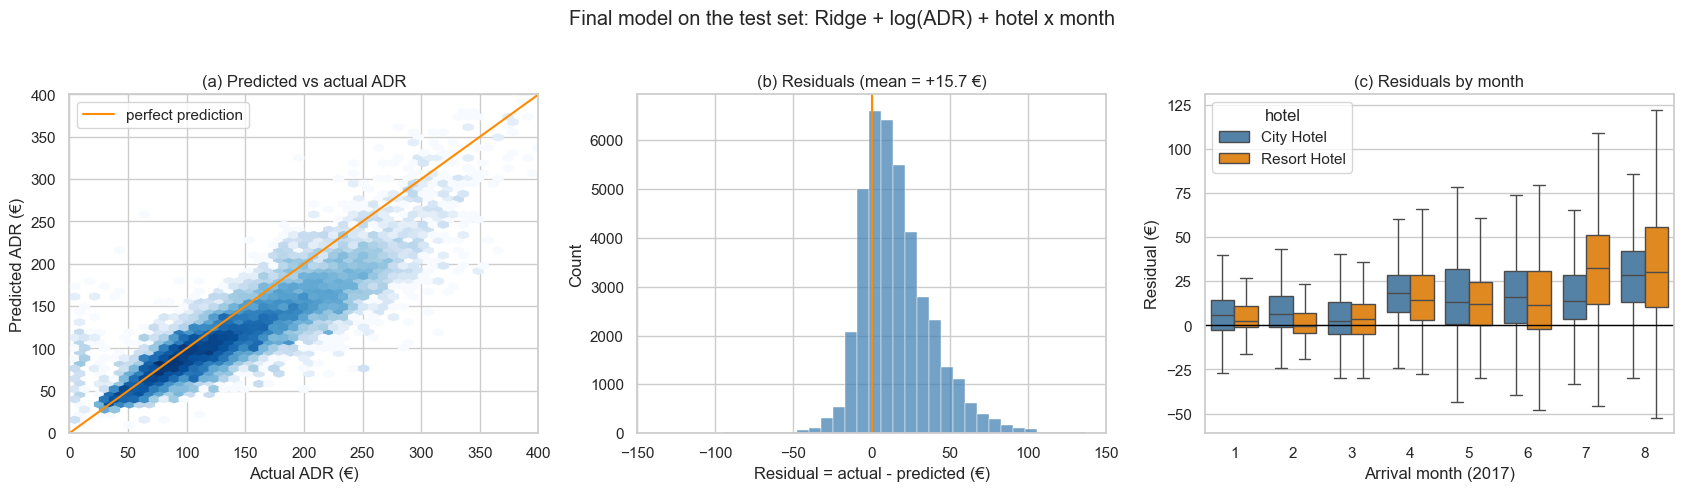

In [32]:
pred_df = df.loc[X_test_reg.index, ["hotel", "arrival_month_num"]].assign(
    actual=y_test_reg, predicted=final_model.predict(X_test_reg[final_features]))
pred_df["residual"] = pred_df["actual"] - pred_df["predicted"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) Predicted vs actual
axes[0].hexbin(pred_df["actual"], pred_df["predicted"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
axes[0].plot([0, 400], [0, 400], color="darkorange", lw=1.5, label="perfect prediction")
axes[0].set(xlim=(0, 400), ylim=(0, 400), xlabel="Actual ADR (€)", ylabel="Predicted ADR (€)",
            title="(a) Predicted vs actual ADR")
axes[0].legend(loc="upper left")

# (b) Residual distribution
sns.histplot(pred_df["residual"], bins=80, ax=axes[1], color="steelblue")
axes[1].axvline(0, color="darkorange", lw=1.5)
axes[1].set(xlim=(-150, 150), xlabel="Residual = actual - predicted (€)",
            title=f"(b) Residuals (mean = {pred_df['residual'].mean():+.1f} €)")

# (c) Residuals by arrival month and hotel
sns.boxplot(data=pred_df, x="arrival_month_num", y="residual", hue="hotel", ax=axes[2],
            showfliers=False, palette=["steelblue", "darkorange"])
axes[2].axhline(0, color="black", lw=1)
axes[2].set(xlabel="Arrival month (2017)", ylabel="Residual (€)", title="(c) Residuals by month")

plt.suptitle(f"Final model on the test set: {FINAL_REG}", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation.**
- **(a)** The predictions follow the diagonal, but the highest prices (above about €200) are underestimated.
- **(b)** The residuals are centred on **+€15.7**, not on 0: the model under-predicts the 2017 prices.
- **(c)** This bias is small in winter and grows until August (about +€30), the months where prices rose the most
  (section 6.1). The model reproduces the **2016 price level**.

### 6.4 Which variables drive the price? Testing H3

The final model is trained again on **each group of variables alone**:
- **Product & calendar** (10 variables): hotel, room type, meal, arrival month, hotel × month, day, weekday, nights.
- **Customer & channel** (20 variables): all the others (lead time, group composition, country, segment, channel,
  agent, history, deposit, customer type, special requests...).

In [33]:
# H3: the same model (Ridge on log(ADR)) trained on each group of variables alone
PRODUCT_CALENDAR = ["hotel", "reserved_room_type", "meal", "arrival_month_num", "hotel_month",
                    "arrival_date_day_of_month", "arrival_weekday", "stays_in_weekend_nights",
                    "stays_in_week_nights", "total_nights"]
CUSTOMER_PROFILE = [c for c in REG_FEATURES_LIN if c not in PRODUCT_CALENDAR]

train_and_evaluate_reg("Product & calendar only", Ridge(), ALPHAS, features=PRODUCT_CALENDAR, log_target=True)
train_and_evaluate_reg("Customer & channel only", Ridge(), ALPHAS, features=CUSTOMER_PROFILE, log_target=True)

h3 = pd.DataFrame(reg_results).T.loc[["Product & calendar only", "Customer & channel only", FINAL_REG],
                                     ["rmse", "mae", "r2"]].astype(float).round(3)
h3.insert(0, "n_variables", [len(PRODUCT_CALENDAR), len(CUSTOMER_PROFILE), len(final_features)])
h3

,n_variables,rmse,mae,r2
Product & calendar only,10,35.257,25.579,0.524
Customer & channel only,20,46.998,33.304,0.154
Ridge + log(ADR) + hotel x month,30,28.251,20.298,0.694


**Interpretation.** Product & calendar alone reach an R² of **0.52**, close to the full model (0.69). Customer &
channel alone only reach **0.15** (RMSE €47.0, against €54.5 for the Dummy). **H3 is confirmed**: the price depends mainly on
*what is sold and when*. The customer variables add some information (0.52 to 0.69), but they are not the main
driver.

### 6.5 Critical discussion

**What the model does.** It predicts the **price the hotel charged** for bookings that were made: it describes the
hotel's pricing policy. It is **not a price-response function** that measures how *demand*
changes when the *price* changes. Here demand is not modelled, and the data do not contain the customers who saw
a price and did not book for instance.

**Endogeneity.** Estimating demand from these data with a simple regression would not work either. The price is endogenous when the seller sets it according to the demand he expects, or when an omitted variable
affects both price and demand. In this dataset, the Resort Hotel is about four times more expensive
in August than in November, and August is also its busiest month. A naive regression would conclude that higher
prices attract more guests, while in reality the hotel raises its prices **because** it expects strong demand. The
variables behind this decision (remaining capacity, competitor prices, events) are not in the data. For the same
reason, the coefficients of section 6.4 are associations, not causal effects.

**Conclusion.** The O2 model describes the prices charged well (R² 0.69 on 2017) and supports H3. It can be used to
describe prices or estimate the revenue of a booking, but not to choose the optimal price.

## 7. Unsupervised Learning: Customer Segmentation

**Objective.** Group the bookings according to their **behaviour**, without using any target, and see whether
natural customer segments appear.

**Hypothesis H4.** The behavioural clusters correspond to the commercial segments declared by the hotel
(`market_segment`).

**Methods.** k-means (main method), Gaussian mixture model and hierarchical clustering for comparison, and PCA to
visualise the clusters in two dimensions.

### 7.1 Variables and preprocessing

- **Sample**: duplicates removed (one row per real booking, section 2.9), ADR > 0 and at least one night.
- **8 behavioural variables**: lead time, number of nights, adults, children + babies (`kids`), ADR, special
  requests, parking request (0/1) and repeated guest (0/1).
- **Not used for the clustering**, but used afterwards to describe the clusters: `is_canceled`, the hotel, the
  season, and `market_segment` (needed to test H4 in section 7.6).
- Only numerical and binary variables are used, so no special method for categorical data is needed.
- **Preprocessing**: log transformation of the three skewed variables (lead time, nights, ADR), then
  standardisation. k-means is based on distances, so without standardisation the ADR (about 100) would dominate the
  number of adults (about 2).

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# One row per real booking: duplicates removed, ADR > 0 and at least one night
clu_df = df[(df["is_duplicate"] == 0) & (df["adr"] > 0) & (df["total_nights"] > 0)].copy()
clu_df["kids"] = clu_df["children"] + clu_df["babies"]
clu_df["has_parking"] = (clu_df["required_car_parking_spaces"] > 0).astype(int)

CLU_FEATURES = ["lead_time", "total_nights", "adults", "kids", "adr",
                "total_of_special_requests", "has_parking", "is_repeated_guest"]

X_clu = clu_df[CLU_FEATURES].astype(float)
skewed = ["lead_time", "total_nights", "adr"]
X_clu[skewed] = np.log1p(X_clu[skewed])           # reduce the weight of extreme values
X_clu = StandardScaler().fit_transform(X_clu)      # same scale for all variables (mean 0, std 1)

# Random sample for the slower computations (silhouette, hierarchical clustering, plots)
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_clu), 5000, replace=False)
print(f"Clustering sample: {len(clu_df):,} bookings x {len(CLU_FEATURES)} variables "
      f"(sample of {len(sample_idx):,} for silhouette and hierarchical clustering)")

Clustering sample: 85,577 bookings x 8 variables (sample of 5,000 for silhouette and hierarchical clustering)


### 7.2 Choosing the number of clusters (k-means)

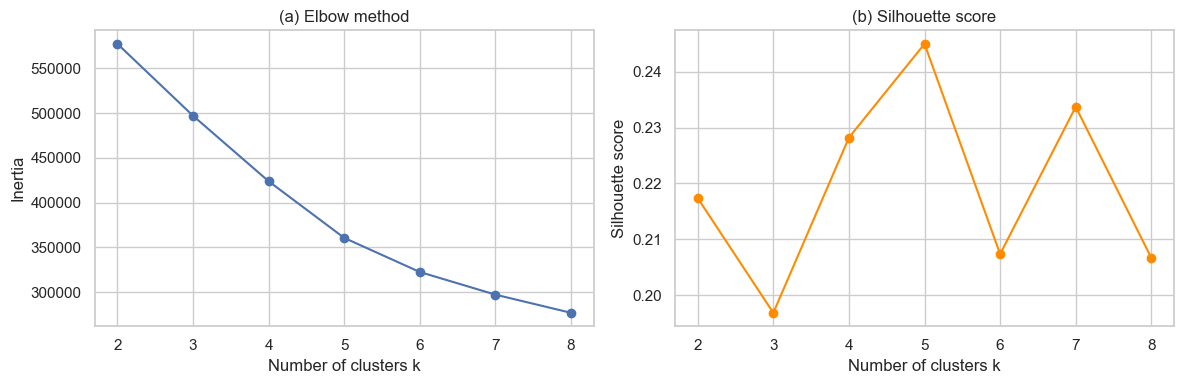

Chosen number of clusters: k = 5 (highest silhouette = 0.245)


In [35]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_clu)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_clu[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, marker="o")
axes[0].set(xlabel="Number of clusters k", ylabel="Inertia", title="(a) Elbow method")
axes[1].plot(ks, silhouette, marker="o", color="darkorange")
axes[1].set(xlabel="Number of clusters k", ylabel="Silhouette score", title="(b) Silhouette score")
plt.tight_layout()
plt.show()

K = ks[int(np.argmax(silhouette))]
print(f"Chosen number of clusters: k = {K} (highest silhouette = {max(silhouette):.3f})")

**Interpretation.**
- **(a)** The inertia (distance of the bookings to their cluster centre) decreases regularly: there is no clear elbow.
- **(b)** The silhouette score is highest for **k = 5** (0.245), which is chosen.
- A silhouette of about 0.25 is low (1 = perfectly separated clusters): the clusters exist but **overlap**. Customer
  behaviour is a continuum rather than a set of clearly separated groups.

### 7.3 Comparing clustering algorithms

The three methods use the same k = 5 and are scored on the same 5,000 bookings:
- **k-means**: each booking goes to the nearest cluster centre.
- **Gaussian mixture**: each cluster is a Gaussian distribution, which allows clusters of different shapes.
- **Hierarchical clustering (Ward)**: bookings are merged step by step into larger groups. It is slow on large data
  sets, so it is only run on the sample.

In [36]:
kmeans_labels = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_clu)
gmm_labels = GaussianMixture(n_components=K, random_state=RANDOM_STATE).fit(X_clu).predict(X_clu)
hier_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_clu[sample_idx])  # sample only

# All methods are scored on the same 5,000 bookings
X_s = X_clu[sample_idx]
clu_comparison = pd.DataFrame({
    name: {"silhouette (higher = better)": silhouette_score(X_s, lab),
           "Davies-Bouldin (lower = better)": davies_bouldin_score(X_s, lab),
           "Calinski-Harabasz (higher = better)": calinski_harabasz_score(X_s, lab),
           "smallest cluster (%)": 100 * np.bincount(lab).min() / len(lab)}
    for name, lab in [("k-means", kmeans_labels[sample_idx]),
                      ("Gaussian mixture", gmm_labels[sample_idx]),
                      ("Hierarchical (Ward)", hier_labels)]}).T
clu_comparison.round(3)

,silhouette (higher = better),Davies-Bouldin (lower = better),Calinski-Harabasz (higher = better),smallest cluster (%)
k-means,0.245,1.303,1089.745,3.46
Gaussian mixture,0.181,1.606,851.560,2.68
Hierarchical (Ward),0.256,1.347,1030.852,3.46


**Interpretation.**
- **k-means** and **hierarchical clustering** give very similar results (silhouette 0.245 and 0.256,
  Davies-Bouldin 1.30 and 1.35), and their smallest cluster has the same size. The two methods find the same
  structure, which makes it more credible.
- The **Gaussian mixture** is worse on all three scores. The binary variables (parking, repeated guest) do not
  follow a Gaussian distribution.
- **k-means is kept**: it is as good as hierarchical clustering and, unlike it, it can be run on all 85,577
  bookings.

### 7.4 Visualisation with PCA

Variance explained: PC1 = 24.6%, PC2 = 16.3%, total = 40.8%


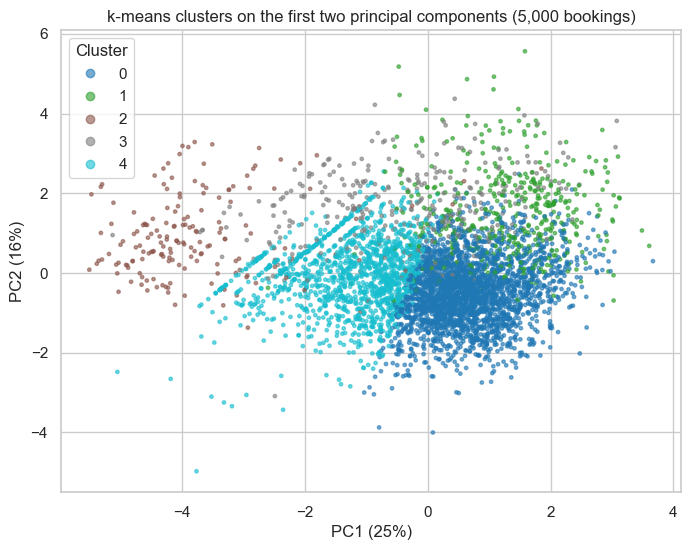

In [40]:
pca = PCA(n_components=2).fit(X_clu)
X_2d = pca.transform(X_clu[sample_idx])
var = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {var[0]:.1%}, PC2 = {var[1]:.1%}, total = {var.sum():.1%}")

fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels[sample_idx], cmap="tab10", s=6, alpha=0.6)
ax.legend(*points.legend_elements(), title="Cluster")
ax.set(xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})",
       title="k-means clusters on the first two principal components (5,000 bookings)")
plt.show()

**Interpretation.**
- **PC1** is high for long, early-booked stays with several adults; **PC2** is high for families, high ADR and
  parking.
- The clusters occupy different areas but touch each other, which confirms the low silhouette score: there are no
  clear boundaries between segments.

### 7.5 Cluster profiles and business segments

In [48]:
clu_df["cluster"] = kmeans_labels
profile = clu_df.groupby("cluster").agg(
    bookings=("adr", "size"),
    lead_time=("lead_time", "mean"),
    nights=("total_nights", "mean"),
    adults=("adults", "mean"),
    kids=("kids", "mean"),
    adr=("adr", "mean"),
    repeated_guest=("is_repeated_guest", "mean"),
    cancellation_rate=("is_canceled", "mean"),
    resort_share=("hotel", lambda s: (s == "Resort Hotel").mean()),
    summer_share=("season", lambda s: (s == "Summer").mean()))
profile.insert(1, "share_%", 100 * profile["bookings"] / len(clu_df))
profile.round(2)

,bookings,share_%,lead_time,nights,adults,kids,adr,repeated_guest,cancellation_rate,resort_share,summer_share
cluster,,,,,,,,,,,
0,45898,53.63,112.65,4.58,2.07,0.00,110.03,0.0,0.35,0.34,0.38
1,7949,9.29,93.41,4.09,1.96,1.48,160.93,0.0,0.39,0.39,0.51
2,2918,3.41,19.16,2.12,1.33,0.03,75.28,1.0,0.08,0.54,0.19
3,6186,7.23,57.59,3.26,1.94,0.10,112.46,0.0,0.00,0.76,0.33
4,22626,26.44,25.78,2.00,1.53,0.01,90.19,0.0,0.20,0.36,0.20


**Interpretation: five business segments.**

| Cluster | Name | Share | Main features | Cancellation | Possible rate fence |
|---|---|---|---|---|---|
| 0 | **Planned leisure stays** | 54% | Booked 113 days ahead, 4.6 nights, couples | 35% | Advance purchase, non-refundable rates (time-based differentiation) |
| 1 | **Families** | 9% | 1.5 children, highest ADR (€161), 51% in summer | 39% | Product versioning: family rooms, meal packages |
| 2 | **Loyal business guests** | 3% | Repeated guests, booked 19 days ahead, 2 nights, 49% Corporate | 8% | Group pricing: negotiated corporate rates |
| 3 | **Guests coming by car** | 7% | All ask for parking, 76% Resort Hotel | 0% | Package offers including parking |
| 4 | **Last-minute short stays** | 26% | Booked 26 days ahead, 2 nights, 1–2 adults, 64% City Hotel | 20% | Time-based differentiation (late booking) |

**Link with Phillips book.** Price differentiation means charging different prices to segments with different
willingness to pay. Since the hotel cannot see the willingness to pay of each customer, it uses
**fences**: conditions that customers accept or not, such as booking early, accepting a non-refundable rate, or
belonging to a company with a contract.

### 7.6 Testing H4: clusters vs `market_segment`

In [43]:
print(f"Adjusted Rand Index vs market_segment: k-means = {adjusted_rand_score(clu_df['market_segment'], kmeans_labels):.3f}"
      f" | Gaussian mixture = {adjusted_rand_score(clu_df['market_segment'], gmm_labels):.3f}")

# Share of each market segment inside each cluster (%)
pd.crosstab(clu_df["cluster"], clu_df["market_segment"], normalize="index").mul(100).round(0)

Adjusted Rand Index vs market_segment: k-means = 0.075 | Gaussian mixture = 0.026


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
cluster,,,,,,,
0,0.0,0.0,1.0,8.0,6.0,19.0,67.0
1,0.0,0.0,0.0,17.0,1.0,7.0,75.0
2,2.0,0.0,49.0,24.0,2.0,7.0,16.0
3,0.0,0.0,5.0,27.0,4.0,8.0,55.0
4,1.0,0.0,9.0,19.0,8.0,15.0,48.0


**Interpretation.**
- The **Adjusted Rand Index** measures the agreement between two groupings: 1 = identical, 0 = no more agreement than
  chance. Here it is **0.075** for k-means (0.026 for the Gaussian mixture): almost no agreement.
- `Online TA` is the main segment in four clusters out of five. Only cluster 2 (loyal business guests) is clearly
  linked to one segment (49% Corporate).

**Verdict: H4 is refuted.** The commercial segment describes **how** the room was sold (channel, contract), not
**how** the customer behaves. The same channel (online travel agencies) sells planned holidays, family stays and
last-minute city breaks. For revenue management, the behavioural clusters give information that the declared
segment does not contain.

### 7.7 Conclusion

- k-means finds **five behavioural segments** (planned leisure stays, families, loyal business guests, guests coming
  by car, last-minute short stays), confirmed by hierarchical clustering.
- The segments overlap: customer behaviour is a continuum.
- They do **not** match the commercial segments (ARI 0.075): **H4 is refuted**.

## 8. Bonus: Overbooking Simulation

**Hypothesis H2.** Overbooking with the **individual ML cancellation probabilities** gives a better result (net
revenue, denied guests) than overbooking with a **single average cancellation rate**.

### 8.1 Assumptions
- **Capacity**: maximum number of rooms occupied on one night in 2015/2016. The real hotel never had more guests than
  that, so no policy could ever deny a guest: the simulation uses **80% of this capacity** (stress test).
- **Price `p`**: observed ADR. **Cost of a denied guest `D`**: 2 × mean ADR (City), 5 × mean ADR (Resort), because
  overbooking is rare in resort hotels, where relocating a guest is costly.

In [44]:
def explode_nights(data):
    """One row per (booking, night): a booking of 3 nights becomes 3 rows."""
    data = data[data["total_nights"] > 0]
    out = data.loc[data.index.repeat(data["total_nights"])].copy()
    out["night"] = out["arrival_date"] + pd.to_timedelta(out.groupby(level=0).cumcount(), unit="D")
    return out

# 1. Capacity = maximum number of occupied rooms on one night (non-cancelled bookings, training period)
occupancy = explode_nights(df[df["is_canceled"] == 0]).groupby(["hotel", "night"]).size()
CAPACITY = occupancy[occupancy.index.get_level_values("night") < SPLIT_DATE].groupby("hotel").max()
SIM_CAPACITY = (0.8 * CAPACITY).round().astype(int)   # stress test, see the text

# 2. Show probability of each test booking: ML model vs single average rate
FINAL_CLF = results_df.index[0]   # best classifier of Phase 5
test_ob = df.loc[X_test_clf.index, ["hotel", "arrival_date", "booking_date", "total_nights", "adr", "is_canceled"]].copy()
test_ob["q_ml"] = 1 - clf_models[FINAL_CLF].predict_proba(X_test_clf)[:, 1]
train_cancel_rate = y_train_clf.groupby(df.loc[X_train_clf.index, "hotel"]).mean()
test_ob["q_avg"] = 1 - test_ob["hotel"].map(train_cancel_rate)

# 3. Cost D of a denied guest: much higher for the Resort Hotel (Phillips, ch. 11)
mean_adr = df.loc[X_train_clf.index].groupby("hotel")["adr"].mean()
D_COST = pd.Series({"City Hotel": 2 * mean_adr["City Hotel"], "Resort Hotel": 5 * mean_adr["Resort Hotel"]})

# Nights of the test period (January - August 2017)
test_nights = explode_nights(test_ob)
test_nights = test_nights[test_nights["night"] < "2017-09-01"]

print(f"Classifier used: {FINAL_CLF}")
pd.DataFrame({"max occupancy": CAPACITY,
              "simulated capacity C": SIM_CAPACITY,
              "D (€)": D_COST.round(0),
              "cancel rate train": train_cancel_rate,
              "cancel rate test (actual)": test_ob.groupby("hotel")["is_canceled"].mean(),
              "cancel rate test (ML mean)": 1 - test_ob.groupby("hotel")["q_ml"].mean()}).round(3)

Classifier used: Gradient boosting


,max occupancy,simulated capacity C,D (€),cancel rate train,cancel rate test (actual),cancel rate test (ML mean)
City Hotel,226,181,198.0,0.414,0.426,0.386
Resort Hotel,187,150,441.0,0.263,0.308,0.186


**Note.** The ML model underestimates the 2017 cancellations, especially for the Resort Hotel (18.6% predicted vs
30.8% actual).

### 8.2 Simulation
For each night, bookings arrive in booking order and are accepted if `p ≥ D × P(hotel already full)`, which maximises
`R = p × shows − D × max(shows − C, 0)`. `P(hotel already full)` is estimated by Monte-Carlo (1,000
simulations of the shows). The result is measured with the real cancellations.

In [45]:
N_SIM = 1000
rng = np.random.default_rng(RANDOM_STATE)
POLICIES = ["No overbooking", "Average cancellation rate", "ML probabilities"]

def simulate_night(night, C, D, policy):
    """The bookings of one night arrive in booking order and the policy accepts or refuses each one.
    The result uses the real outcome (cancelled or not) of the accepted bookings."""
    night = night.sort_values("booking_date")
    price = night["adr"].to_numpy()
    showed = night["is_canceled"].to_numpy() == 0
    q = night["q_ml" if policy == "ML probabilities" else "q_avg"].to_numpy()

    accepted = np.zeros(len(night), dtype=bool)
    sim_shows = np.zeros(N_SIM)   # Monte-Carlo: N_SIM possible numbers of shows among the accepted bookings
    for i in range(len(night)):
        if policy == "No overbooking":
            accept = accepted.sum() < C
        else:
            p_full = np.mean(sim_shows >= C)     # probability that the hotel is already full
            accept = price[i] >= D * p_full      # risk-based rule: expected revenue >= expected denial cost
        if accept:
            accepted[i] = True
            sim_shows += rng.random(N_SIM) < q[i]   # each simulation: this booking shows with probability q

    shows = accepted & showed
    denied = max(shows.sum() - C, 0)
    return {"accepted": accepted.sum(),
            "net_revenue_k€": (price[shows].sum() - D * denied) / 1000,   # R = p*s - D*(s - C)+  (Phillips 11.1)
            "denied_guests": denied,
            "empty_rooms": max(C - shows.sum(), 0)}

### 8.3 Results

In [49]:
rows = [{"hotel": hotel, "policy": policy, **simulate_night(night, SIM_CAPACITY[hotel], D_COST[hotel], policy)}
        for (hotel, _), night in test_nights.groupby(["hotel", "night"])
        for policy in POLICIES]

overbooking = (pd.DataFrame(rows).groupby(["hotel", "policy"]).sum()
               .reindex(pd.MultiIndex.from_product([D_COST.index, POLICIES], names=["hotel", "policy"])))
no_ob = overbooking.xs("No overbooking", level="policy")["net_revenue_k€"]
overbooking["revenue vs no overbooking (%)"] = 100 * (overbooking["net_revenue_k€"]
                                                      / no_ob.reindex(overbooking.index.get_level_values("hotel")).values - 1)
overbooking.round(1)

accepted  net_revenue_k€  \
hotel        policy                                                
City Hotel   No overbooking                43746          2325.4   
             Average cancellation rate     74656          4382.5   
             ML probabilities              75425          4635.3   
Resort Hotel No overbooking                34989          1929.2   
             Average cancellation rate     45759          2771.0   
             ML probabilities              44808          2722.3   

                                        denied_guests  empty_rooms  \
hotel        policy                                                  
City Hotel   No overbooking                         0        22372   
             Average cancellation rate           1660         5427   
             ML probabilities                     500         4059   
Resort Hotel No overbooking                         0        14752   
             Average cancellation rate             58         7529   
             ML probabilities                       2         8254   

                                        revenue vs no overbooking (%)  
hotel        policy                                                    
City Hotel   No overbooking                                       0.0  
             Average cancellation rate                           88.5  
             ML probabilities                                    99.3  
Resort Hotel No overbooking                                       0.0  
             Average cancellation rate                           43.6  
             ML probabilities                                    41.1

**Interpretation** (counts in room-nights).
- **Overbooking pays**: +88% to +100% net revenue (City) and +41% to +44% (Resort) vs no overbooking.
- **City Hotel**: the ML policy is better on everything: +5.9% revenue vs the average rate and 3 times fewer denied
  guests (500 vs 1,660).
- **Resort Hotel**: the ML policy almost never denies a guest (2 vs 58) but earns 1.9% less, because it underestimates
  the 2017 cancellations and is too cautious.

**Verdict: H2 is confirmed for the City Hotel and only partly for the Resort Hotel.** ML probabilities improve
overbooking only if they stay well calibrated, so the model must be re-estimated regularly. Limits: the 80%
capacity and `D` are assumptions, and each night is treated separately.